In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [29]:
df = pd.read_csv("VEIL_Email_SMS-Dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [30]:
df.head()

,input_type,content,subject,recipient,label,message_length,word_count,character_count,url_count,contains_url,urgency_keyword_count,exclamation_count,digit_count,uppercase_ratio,has_subject,text_type
0,sms,A delivery issue was reported. Check your orde...,Not applicable,notice@alerts.test,spam,145,22,145,1,Yes,0,0,0,0.0339,No,plain_text
1,email,A subscription or account setting may require ...,Benefits enrollment reminder,team@example.org,phishing,177,26,177,1,Yes,1,0,0,0.0274,Yes,plain_text
2,email,A payment or invoice needs attention. Review t...,Password reset request,support@example.org,phishing,214,33,214,1,Yes,1,0,0,0.0286,Yes,plain_text
3,sms,Please call me when you get a chance. Thanks.,Not applicable,team@company.example.org,legitimate,45,9,45,0,No,0,0,0,0.0571,No,plain_text
4,email,The message requests urgent action. Verify the...,Payment confirmation needed,updates@company.example.org,phishing,120,15,120,0,No,1,0,0,0.0192,Yes,plain_text


In [31]:
df.tail()

,input_type,content,subject,recipient,label,message_length,word_count,character_count,url_count,contains_url,urgency_keyword_count,exclamation_count,digit_count,uppercase_ratio,has_subject,text_type
21031,sms,A refund status is available. Check the transa...,Not applicable,team@school.example.edu,spam,202,31,202,1,Yes,1,0,0,0.0303,No,plain_text
21032,email,Please review your account details as soon as ...,Security notice for your account,contact@mail.example.com,phishing,136,21,136,0,No,0,0,0,0.0177,Yes,plain_text
21033,email,This is a routine reminder about the event. Co...,Appointment confirmation,contact@unknown-sender.test,legitimate,102,17,102,0,No,0,0,0,0.0238,Yes,plain_text
21034,sms,Please remember to bring the notebook tomorrow...,Not applicable,contact@unknown-sender.test,legitimate,73,13,73,0,No,0,0,0,0.0339,No,plain_text
21035,sms,I am on the bus now and should arrive soon. Pl...,Not applicable,support@company.example.org,legitimate,75,15,75,0,No,0,0,0,0.0339,No,plain_text


In [32]:
df.sample(6, random_state=42)

,input_type,content,subject,recipient,label,message_length,word_count,character_count,url_count,contains_url,urgency_keyword_count,exclamation_count,digit_count,uppercase_ratio,has_subject,text_type
13855,email,Your profile information may need an update. C...,Subscription billing notice,billing@example.org,phishing,192,29,192,1,Yes,1,0,0,0.0253,Yes,plain_text
9457,sms,A refund status is available. Check the transa...,Not applicable,billing@unknown-sender.test,spam,88,14,88,0,No,0,0,0,0.0274,No,plain_text
2501,sms,I sent the document to the group chat.,Not applicable,team@mail.example.com,legitimate,38,8,38,0,No,0,0,0,0.0333,No,plain_text
18894,sms,You may qualify for a special prize. Review th...,Not applicable,billing@unknown-sender.test,spam,184,31,184,1,Yes,1,0,0,0.0340,No,plain_text
1311,sms,Limited-time offer available. Verify the selle...,Not applicable,notice@company.example.org,spam,136,21,136,1,Yes,0,0,0,0.0270,No,plain_text
3882,email,The schedule has been updated. Please check th...,Class schedule update,notice@example.org,legitimate,144,23,144,0,No,0,0,0,0.0254,Yes,plain_text


In [33]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 21036
Total Columns: 16


In [34]:
print("Dataset Columns:\n")

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Dataset Columns:

1. input_type
2. content
3. subject
4. recipient
5. label
6. message_length
7. word_count
8. character_count
9. url_count
10. contains_url
11. urgency_keyword_count
12. exclamation_count
13. digit_count
14. uppercase_ratio
15. has_subject
16. text_type


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21036 entries, 0 to 21035
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   input_type             21036 non-null  object 
 1   content                21036 non-null  object 
 2   subject                21036 non-null  object 
 3   recipient              21036 non-null  object 
 4   label                  21036 non-null  object 
 5   message_length         21036 non-null  int64  
 6   word_count             21036 non-null  int64  
 7   character_count        21036 non-null  int64  
 8   url_count              21036 non-null  int64  
 9   contains_url           21036 non-null  object 
 10  urgency_keyword_count  21036 non-null  int64  
 11  exclamation_count      21036 non-null  int64  
 12  digit_count            21036 non-null  int64  
 13  uppercase_ratio        21036 non-null  float64
 14  has_subject            21036 non-null  object 
 15  te

In [36]:
df.describe()

,message_length,word_count,character_count,url_count,urgency_keyword_count,exclamation_count,digit_count,uppercase_ratio
count,21036.000000,21036.000000,21036.000000,21036.000000,21036.000000,21036.000000,21036.000000,21036.000000
mean,128.343744,20.566458,128.343744,0.364090,0.128114,0.059755,0.405495,0.032760
std,54.901147,7.727662,54.901147,0.481186,0.334224,0.237037,1.403333,0.015646
min,32.000000,5.000000,32.000000,0.000000,0.000000,0.000000,0.000000,0.013700
25%,77.000000,14.000000,77.000000,0.000000,0.000000,0.000000,0.000000,0.025000
50%,139.000000,22.000000,139.000000,0.000000,0.000000,0.000000,0.000000,0.027800
75%,167.000000,26.000000,167.000000,1.000000,0.000000,0.000000,0.000000,0.033900
max,275.000000,40.000000,275.000000,1.000000,1.000000,1.000000,6.000000,0.117600


In [37]:
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal Missing Values:", missing_values.sum())

input_type               0
content                  0
subject                  0
recipient                0
label                    0
message_length           0
word_count               0
character_count          0
url_count                0
contains_url             0
urgency_keyword_count    0
exclamation_count        0
digit_count              0
uppercase_ratio          0
has_subject              0
text_type                0
dtype: int64

Total Missing Values: 0


In [38]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 4965


In [39]:
print(df['label'].value_counts())

label
legitimate    11570
spam           4741
phishing       4725
Name: count, dtype: int64


In [40]:
print((df['label'].value_counts(normalize=True) * 100).round(2))

label
legitimate    55.00
spam          22.54
phishing      22.46
Name: proportion, dtype: float64


### Data Visualization Using Matplotlib

Matplotlib is used to create different charts and graphs for the VEIL dataset. These visualizations help analyse message labels, email and SMS distribution, message length and URL frequency.

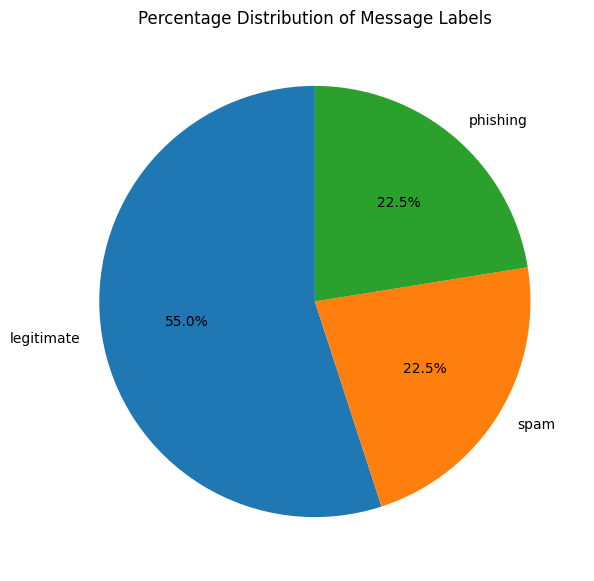

In [41]:
label_percent = df['label'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 7))

plt.pie(
    label_percent,
    labels=label_percent.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Percentage Distribution of Message Labels")
plt.show()

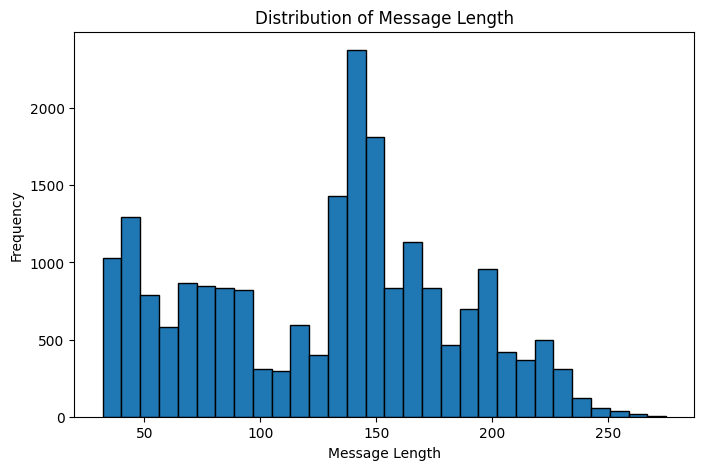

In [42]:
plt.figure(figsize=(8, 5))
plt.hist(df['message_length'], bins=30, edgecolor='black')
plt.title('Distribution of Message Length')
plt.xlabel('Message Length')
plt.ylabel('Frequency')
plt.show()

### Data Visualization Using Seaborn

Seaborn is a Python data visualization library used to create statistical graphs. In the VEIL project, Seaborn is used to analyse message label distribution, compare email and SMS data, visualize message length and examine relationships between numerical features.

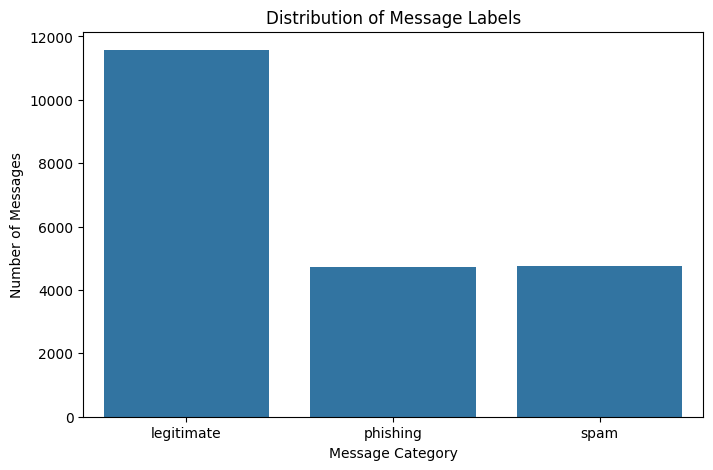

In [43]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='label',
    order=['legitimate', 'phishing', 'spam']
)

plt.title("Distribution of Message Labels")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

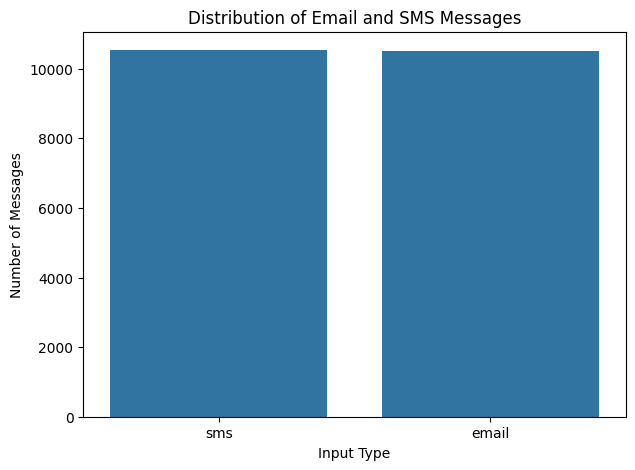

In [44]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='input_type')

plt.title("Distribution of Email and SMS Messages")
plt.xlabel("Input Type")
plt.ylabel("Number of Messages")
plt.show()

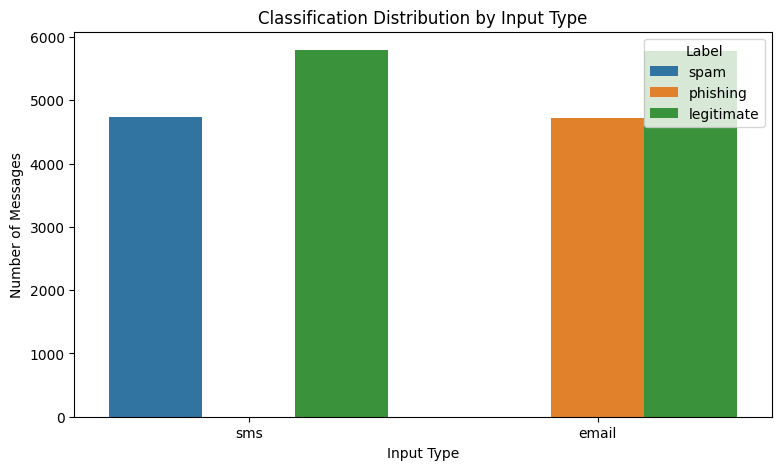

In [45]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='input_type',
    hue='label'
)

plt.title("Classification Distribution by Input Type")
plt.xlabel("Input Type")
plt.ylabel("Number of Messages")
plt.legend(title="Label")
plt.show()

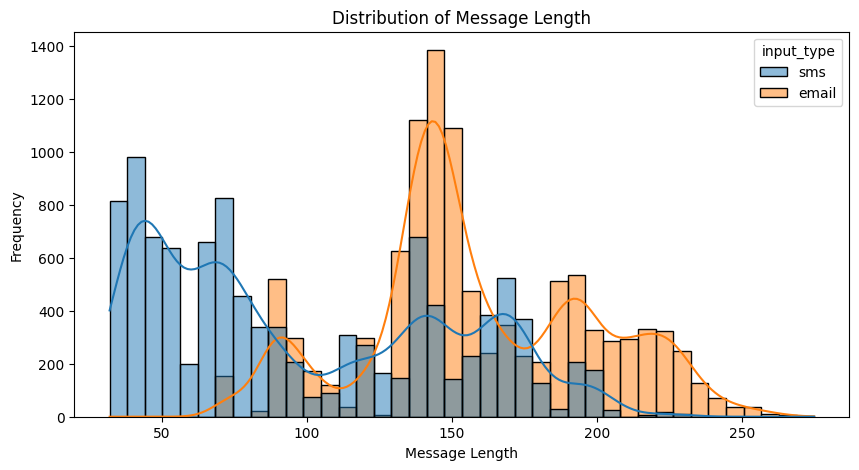

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='input_type',
    bins=40,
    kde=True
)

plt.title("Distribution of Message Length")
plt.xlabel("Message Length")
plt.ylabel("Frequency")
plt.show()

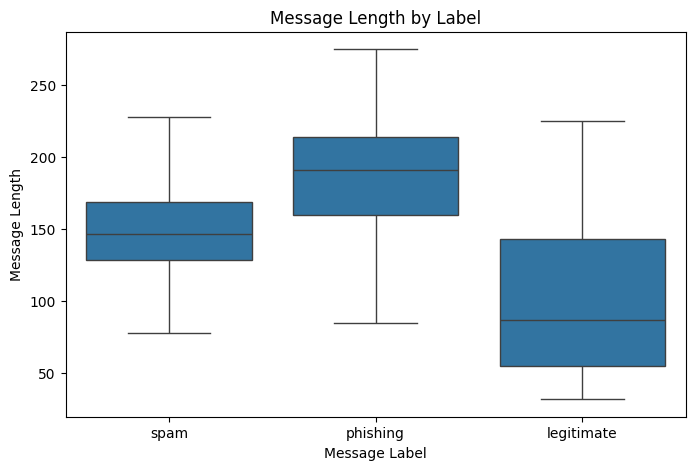

In [47]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='label', y='message_length')
plt.title('Message Length by Label')
plt.xlabel('Message Label')
plt.ylabel('Message Length')
plt.show()

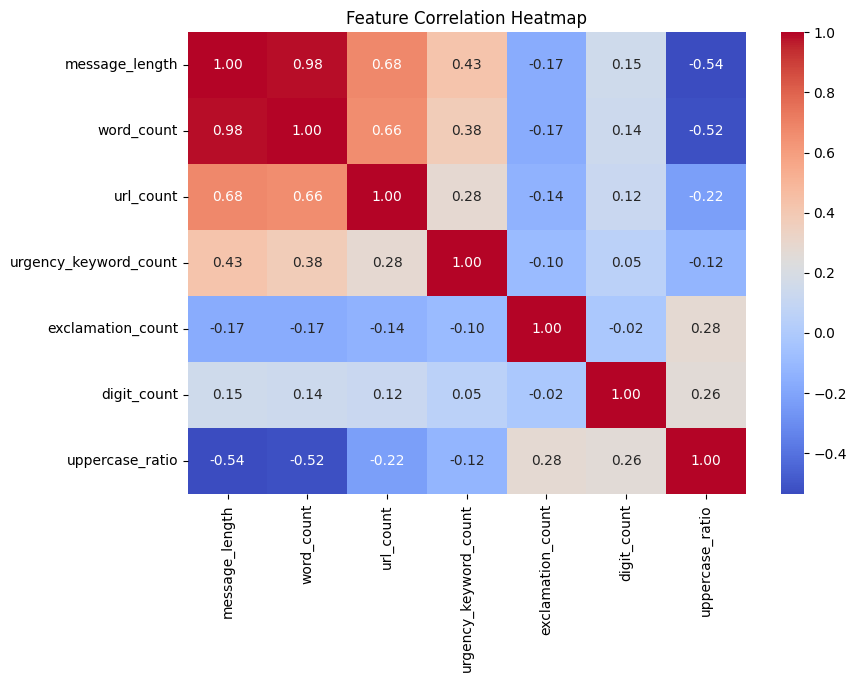

In [48]:
features = [
    'message_length', 'word_count', 'url_count',
    'urgency_keyword_count', 'exclamation_count',
    'digit_count', 'uppercase_ratio'
]

plt.figure(figsize=(9, 6))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

In [49]:
variance = df[features].var().sort_values(ascending=False)

print("Feature Variance:\n")
print(variance)

Feature Variance:

message_length           3014.135935
word_count                 59.716762
digit_count                 1.969343
url_count                   0.231540
urgency_keyword_count       0.111706
exclamation_count           0.056187
uppercase_ratio             0.000245
dtype: float64


### Train-Test Split

Train-test splitting is used to divide the VEIL dataset into two parts. The training dataset is used to train the machine-learning model, while the testing dataset is used to evaluate its performance on unseen data.

In this project, 80% of the data is used for training and 20% for testing.

In [50]:
from sklearn.model_selection import train_test_split

df['target'] = df['label'].map({
    'legitimate': 0,
    'phishing': 1,
    'spam': 1
})

X = df[features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16828, 7)
Testing data: (4208, 7)


### Model Accuracy and Confusion Matrix

The Random Forest model is evaluated using the test dataset to measure its classification performance.

Model accuracy indicates how many messages were correctly classified as legitimate or suspicious (phishing emails and spam SMS).

The confusion matrix provides a detailed comparison between the actual and predicted classifications, showing correct and incorrect predictions for both classes.

In [51]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [52]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 99.36 %


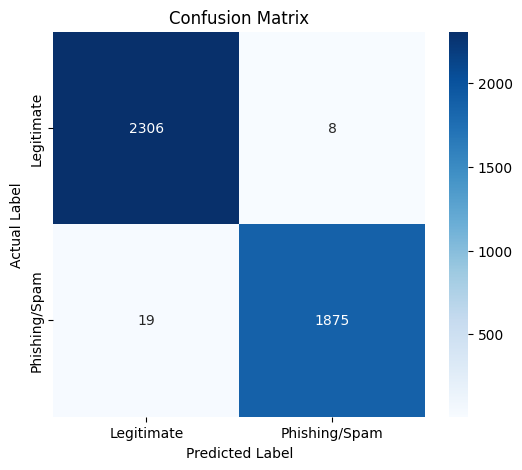

In [53]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Phishing/Spam'],
    yticklabels=['Legitimate', 'Phishing/Spam']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

### R² Score Evaluation

R² (R-Squared) is a statistical measure used to evaluate how well a regression model explains the variation in the target values.

A higher R² score indicates a better fit for a regression model. However, since VEIL uses Random Forest Classification, R² score is not an appropriate evaluation metric for this model.

In [54]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))

R2 Score: 0.9741
